In [16]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
main_pth = '/users/kduecker/hnn-tuning'
import os
import pandas as pd
pth_mod = os.path.join(main_pth, 'local_hnn/hnn_core/mod')
pth_rslts = os.path.join(main_pth, 'new_cells_dev/optuna/ca_spikes_old')
os.makedirs(pth_rslts, exist_ok=True)
figpth = os.path.join(pth_rslts, 'figures')
os.makedirs(figpth, exist_ok=True)
import pickle

from l23_ca_spikes_optuna import reconstruct_params, get_sections_load_mechs

# neuron imports
import neuron
from neuron import h
from neuron.units import ms, mV

neuron.load_mechanisms(pth_mod)
h.load_file("stdrun.hoc")

import sys
sys.path.append(os.path.join(main_pth, 'new_cells_dev/utils'))
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, linear_gbar

from scipy.signal import find_peaks

Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


In [2]:
thresh_no_spikes = (0-4.6)**2/1.7**2

In [3]:
# import optuna
# from optuna.storages import JournalStorage
# from optuna.storages.journal import JournalFileBackend
# sampler_name = 'random'
# study_name = f'l23_ca_spike_cafun'
# journal_file = os.path.join(pth_rslts, f"journal_ca_spike_cafun_{sampler_name}.log")
# complete_study_file = os.path.join(pth_rslts, f'complete_study_ca_spike_cafun_{sampler_name}.pkl')
# study_df_file = os.path.join(pth_rslts, f'study_df_cafun_{sampler_name}.pkl')


# study = optuna.create_study(
#     study_name=study_name,
#     direction='minimize',
#     storage=JournalStorage(JournalFileBackend(file_path=journal_file)),
#     load_if_exists=True)

In [19]:
with open(os.path.join(pth_rslts,'study_df_cafun_tpe.pkl'), 'rb') as f:
        study_ca = pickle.load(f)

(0.0, 1000.0)

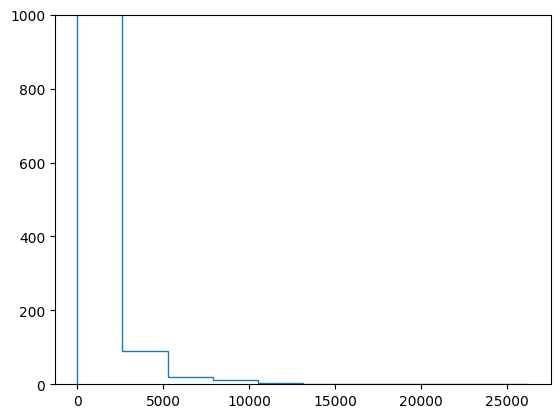

In [20]:
x = study_ca.value.dropna().values
u, c = np.histogram(x, bins=10)
fig, ax = plt.subplots()
ax.stairs(u, c)
ax.set_ylim((0, 1000))

In [21]:
val_unique = np.unique(study_ca.value)

In [22]:
best_fun_study = study_ca.loc[study_ca.value == val_unique[0]]
best_fun_study

,number,value,datetime_start,datetime_complete,duration,params_Ca_HVA_apical,params_Ca_HVA_soma,params_Ca_LVAst_apical,params_Ca_LVAst_soma,params_Ih_apical,...,params_ca_lva_hot_low,params_ca_lva_xkink,params_cm,params_decay,params_e_pas,params_gamma,params_pas_apical,params_pas_basal,params_pas_soma,state
6216,6216,0.055363,2025-09-11 18:54:13.484749,2025-09-11 18:54:14.872200,0 days 00:00:01.387451,0.001137,0.000116,0.003493,0.003005,0.001992,...,193.374930,461.000916,2.804224,252.789633,-65.649208,0.028199,0.000026,0.000106,0.000090,COMPLETE
16096,16096,0.055363,2025-09-11 20:05:02.900165,2025-09-11 20:05:25.528355,0 days 00:00:22.628190,0.003004,0.004653,0.001700,0.004570,0.002793,...,181.588618,316.509337,0.954335,240.534089,-65.579808,0.063316,0.000032,0.000033,0.000033,COMPLETE
16878,16878,0.055363,2025-09-11 20:10:35.238210,2025-09-11 20:10:37.254390,0 days 00:00:02.016180,0.004405,0.004315,0.002068,0.003612,0.004281,...,240.794517,383.217316,0.644479,281.562070,-69.475133,0.078187,0.000059,0.000026,0.000088,COMPLETE
22833,22833,0.055363,2025-09-11 20:52:35.815003,2025-09-11 20:53:19.423349,0 days 00:00:43.608346,0.003035,0.003047,0.000410,0.001806,0.002300,...,248.924070,443.906977,0.535866,168.463063,-69.476191,0.068899,0.000039,0.000047,0.000027,COMPLETE
25318,25318,0.055363,2025-09-11 21:10:08.176722,2025-09-11 21:10:14.223376,0 days 00:00:06.046654,0.004862,0.004226,0.000873,0.002515,0.000937,...,217.547475,459.320783,0.863248,110.245824,-65.428576,0.060397,0.000088,0.000092,0.000081,COMPLETE
31680,31680,0.055363,2025-09-11 21:55:05.233311,2025-09-11 21:55:16.023634,0 days 00:00:10.790323,0.002633,0.002965,0.004570,0.003013,0.002000,...,298.612500,325.691341,1.429821,197.725872,-65.268808,0.009987,0.000028,0.000081,0.000091,COMPLETE
35893,35893,0.055363,2025-09-11 22:26:35.395328,2025-09-11 22:27:47.755267,0 days 00:01:12.359939,0.003059,0.000738,0.002655,0.003847,0.004713,...,248.354786,564.104987,1.490257,124.099121,-70.054773,0.011871,0.000071,0.000041,0.000067,COMPLETE
52742,52742,0.055363,2025-09-12 00:23:58.263085,2025-09-12 00:24:02.871328,0 days 00:00:04.608243,0.001554,0.000841,0.004483,0.003601,0.001551,...,136.951661,329.745495,1.502841,146.266994,-70.895777,0.021371,0.000026,0.000064,0.000052,COMPLETE


Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


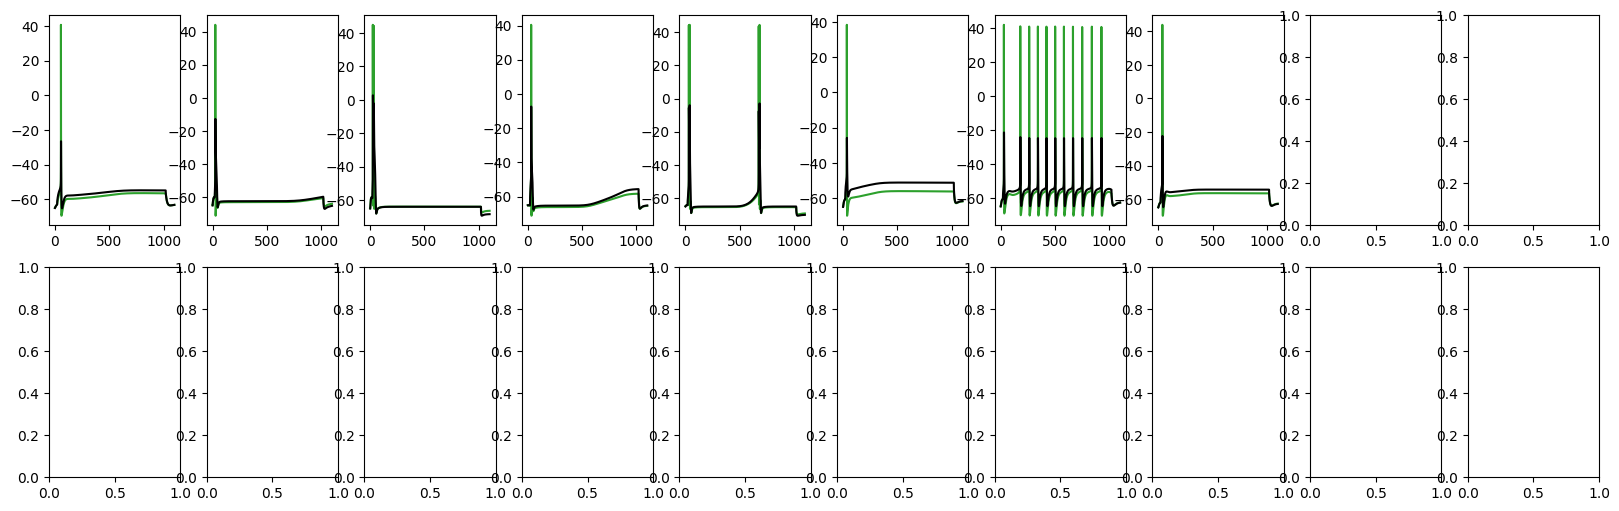

In [23]:
# find the best function study
param_names = ['NaTs2_t_32d_soma','SKv3_1_soma', 'Nap_Et2_soma', 'Ca_HVA_soma', 'Ca_LVAst_soma', 'pas_soma', 'Ih_soma', 'SK_E2_soma', 'Im_soma', 'NaTs2_t_32d_basal', 'SKv3_1_basal', 'Ih_basal', 'pas_basal',
                        'NaTa_t_32d_apical', 'SKv3_1_apical','Ca_HVA_apical', 'Ca_LVAst_apical', 'pas_apical', 'SK_E2_apical', 'Ih_apical', 'Im_apical','decay', 'gamma',
                        'e_pas', 'cm', 'Ra']
ca_param_names = ['ca_hva_dend', 'ca_hva_xkink', 'ca_hva_hot_low', 'ca_hva_hot_high', 'ca_hva_hot_fact', 'ca_lva_dend', 'ca_lva_xkink', 'ca_lva_hot_low', 'ca_lva_hot_high', 'ca_lva_hot_fact']

fig, ax = plt.subplots(2,10,figsize=(20,6))
ax = ax.ravel()
for i, study_idx in enumerate(best_fun_study.index[:20]):
    optim_vals = []
    for key in param_names:
        optim_vals.append(best_fun_study.loc[study_idx]['params_'+key]) 
    ca_vals = []
    # for key in ca_param_names:
    #         ca_vals.append(best_fun_study.loc[study_idx]['params_'+key])

    model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)

    # Get morphological and conductance parameters
    sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

    # Build cell 
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim_sect = 'apical_1'
    stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = 0.25

    t = h.Vector().record(h._ref_t)

    stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
    soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    t_np = t.as_numpy()
    v_np = stim_v.as_numpy()
    s_np = soma_v.as_numpy()

    ax[i].plot(t_np, s_np, color='tab:green')
    ax[i].plot(t_np, v_np, color='k')
    # ax[1,i].plot(t_np, s_np, color='tab:green')
    # ax[1,i].plot(t_np, v_np, color='k')
    # ax[1,i].set_xlim(0, 100)


Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


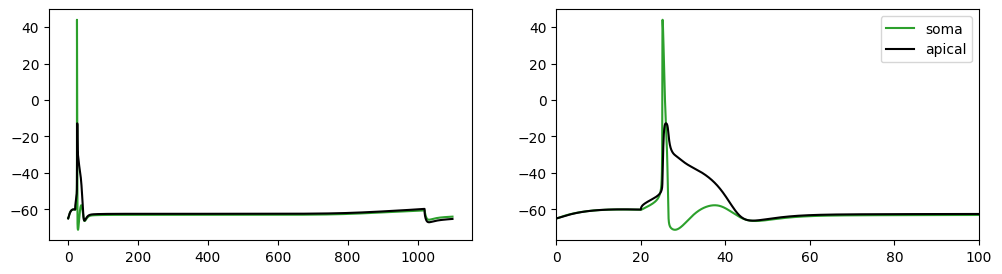

In [27]:
fig, ax = plt.subplots(1,2, figsize=(12,3))
study_idx = best_fun_study.index[1]
optim_vals = []
for key in param_names:
    optim_vals.append(best_fun_study.loc[study_idx]['params_'+key])

model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)

# Get morphological and conductance parameters
sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

# Build cell 
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim_sect = 'apical_1'
stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = 0.25

t = h.Vector().record(h._ref_t)

stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1100 * ms)

t_np = t.as_numpy()
v_np = stim_v.as_numpy()
s_np = soma_v.as_numpy()

ax[0].plot(t_np, s_np, color='tab:green')
ax[0].plot(t_np, v_np, color='k')
ax[1].plot(t_np, s_np, color='tab:green', label='soma')
ax[1].plot(t_np, v_np, color='k', label='apical')
ax[1].set_xlim([0, 100])
ax[1].legend()

fig.savefig(f'{figpth}/ca_spike_cafun.png')

In [25]:
soma_peak = find_peaks(soma_v, height=0, width=0.1)
dend_peak = find_peaks(stim_v, height=-10, width=1)

In [44]:
stim_v = stim_v.as_numpy()
soma_v = soma_v.as_numpy()

In [42]:
np.std(stim_v[int(dend_peak[0][0]):])

7.637781173218526

In [51]:
np.mean(soma_v[-2000:])

-38.7912154185545

In [52]:
if (soma_v[int(dend_peak[0][0]):] > -65).all():
    

True


Mechanisms already loaded from path: /users/kduecker/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


(20.0, 40.0)

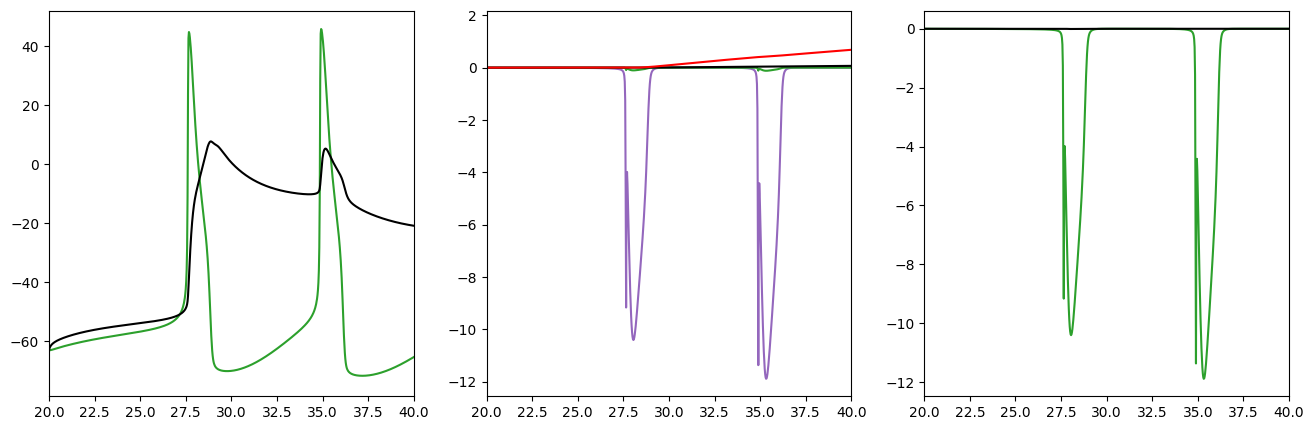

In [137]:
fig, ax = plt.subplots(1,3, figsize=(16,5), sharex=True)
study_idx = best_fun_study.index[6]
optim_vals = []
for key in param_names:
    optim_vals.append(best_fun_study.loc[study_idx]['params_'+key])

model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)
model_params['dend']['Ca_LVAst']*1000000
# Get morphological and conductance parameters
sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

# Build cell 
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, model_params)

stim_sect = 'apical_1'
stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = 0.25

t = h.Vector().record(h._ref_t)

stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_v)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

stim_ca = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_cai)
soma_ca = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_cai)
stim_ica = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_cai)

stim_na = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.5)._ref_ina)
soma_na = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_ina)

h.celsius = 37
h.finitialize()
h.continuerun(1100 * ms)

t_np = t.as_numpy()
v_np = stim_v.as_numpy()
s_np = soma_v.as_numpy()

ax[0].plot(t_np, s_np, color='tab:green')
ax[0].plot(t_np, v_np, color='k')
ax[1].plot(t_np, soma_na, color='tab:purple')


ax[1].plot(t_np, soma_na/100, color='tab:green')
ax[1].plot(t_np, stim_ca, color='k')
ax[1].plot(t_np, stim_ica*10, color='r')

ax[2].plot(t_np, soma_na, color='tab:green')
ax[2].plot(t_np, stim_na, color='k')
ax[0].set_xlim([20, 40])

In [9]:
with open(os.path.join(pth_rslts,'study_df_cafun_tpe.pkl'), 'rb') as f:
        study_ca_round2 = pickle.load(f)

In [10]:
# only look at round 2
study_ca_round2 = study_ca_round2.loc[study_ca_round2.index[study_ca.index[-1]+1:]]

In [18]:
best_study_ca = study_ca_round2.loc[study_ca_round2.value == np.min(study_ca_round2.value)]

In [44]:
best_study_ca.value

61204    1.107266
61229    1.107266
61232    1.107266
61233    1.107266
61236    1.107266
           ...   
62890    1.107266
62915    1.107266
62930    1.107266
62983    1.107266
62988    1.107266
Name: value, Length: 163, dtype: float64

NameError: name 'best_study_ca' is not defined

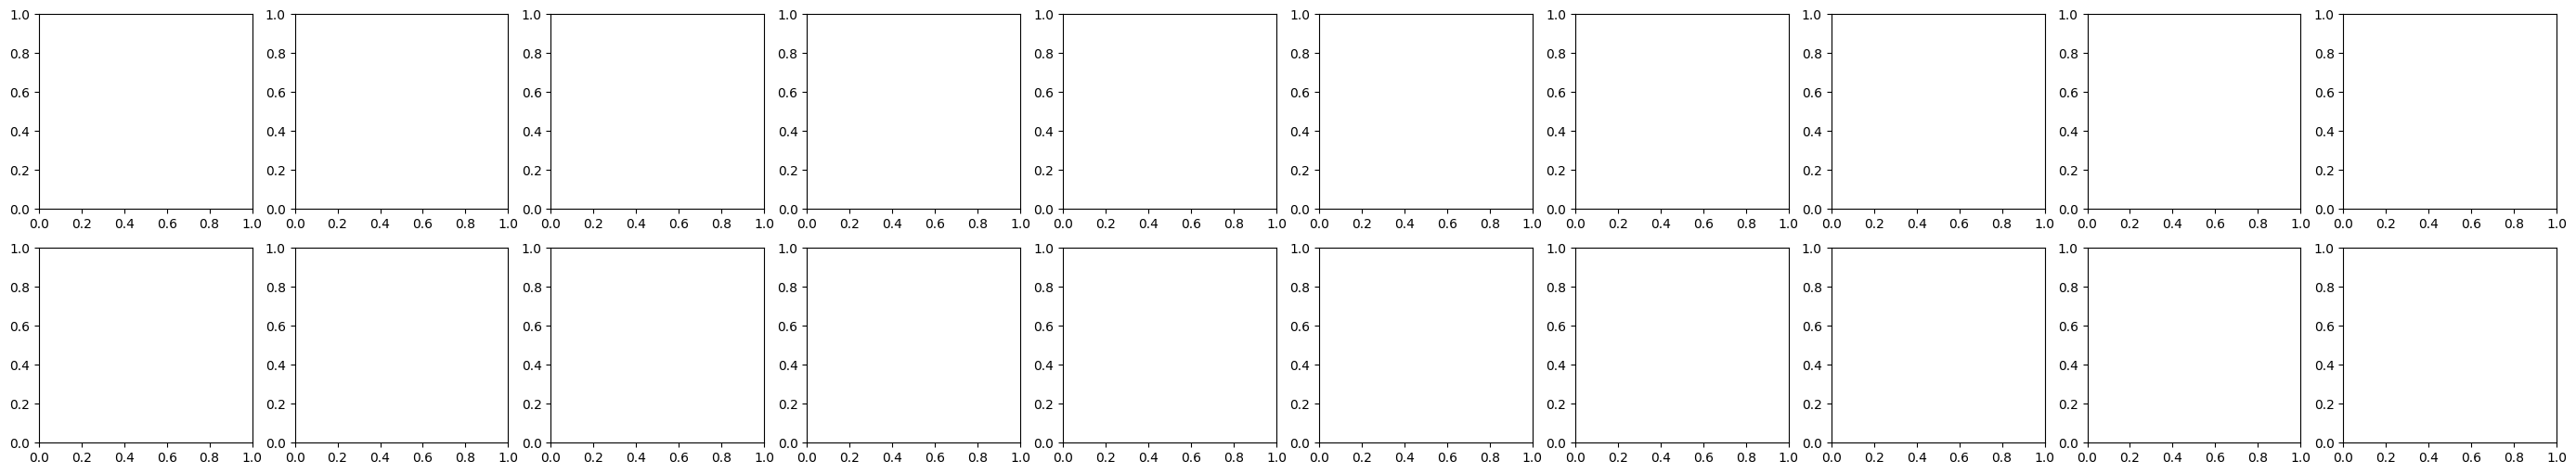

In [9]:
fig, ax = plt.subplots(2,10,figsize=(35,6))
ax = ax.ravel()
for i, study_idx in enumerate(best_study_ca.index[:20]):
    optim_vals = []
    for key in param_names:
        optim_vals.append(best_study_ca.loc[study_idx]['params_'+key]) 
    ca_vals = []
    for key in ca_param_names:
            ca_vals.append(best_study_ca.loc[study_idx]['params_'+key])

    model_params = reconstruct_params(optim_vals, ca_fun_vals=ca_vals)

    # Get morphological and conductance parameters
    sections, mech_class, cell_tree = get_sections_load_mechs(model_params)

    # Build cell 
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, model_params)

    stim_sect = 'apical_tuft'
    stim = h.IClamp(l2pyr._nrn_sections[stim_sect](0.1))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = 0.25

    t = h.Vector().record(h._ref_t)

    stim_v = h.Vector().record(l2pyr._nrn_sections[stim_sect](0.1)._ref_v)
    soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun(1100 * ms)

    t_np = t.as_numpy()
    v_np = stim_v.as_numpy()
    s_np = soma_v.as_numpy()

    ax[i].plot(t_np, s_np, color='tab:green')
    ax[i].plot(t_np, v_np, color='k')

In [61]:
soma_peak = find_peaks(s_np, height=0)
dend_peak = find_peaks(v_np, height=-10, width=1, rel_height=0.5)

In [89]:
dt = h.dt

In [93]:
loss

101061.16122389243

In [92]:
loss = (len(dend_peak[0])-4.6)**2/(1.7)**2 
loss += np.mean((4-pk_dend[1]['widths']*h.dt)**2)/1.4**2
# ensure that spikes are about 250 ms apart (no bursting)
loss += np.mean((250-np.diff(dend_peak[0])*dt)**2)/50**2
loss += np.mean((250-np.diff(soma_peak[0])*dt)**2)/50**2

# penalize soma bursting
if len(soma_peak[0]) > len(dend_peak[0]):
    loss *= 100
elif len(dend_peak[0]) >= len(soma_peak[0]):
    # soma peak should follow dendrite peak
    loss += (1-(sp-dend_peak[0]*h.dt))**2/(0.25**2)  # Gooch, 2022, Gidon, 2020

In [71]:
pk_dend = find_peaks(v_np, height=-10, width=.1)

In [87]:
sp = soma_peak[0][:5]
(1-(sp-dend_peak[0]*h.dt))**2

array([ 217925.580625,  705390.015625, 1550709.825625, 2792491.655625,
       4575962.7225  ])

In [80]:
(soma_peak[0]-dend_peak[0])

ValueError: operands could not be broadcast together with shapes (8,) (5,) 

(0.0, 100.0)

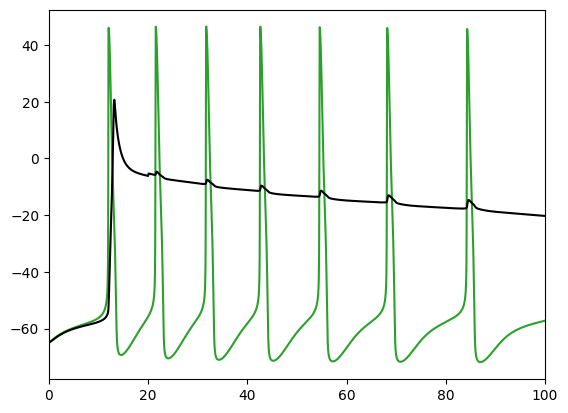

In [66]:
plt.plot(t_np, s_np, color='tab:green')
plt.plot(t_np, v_np, color='k')
plt.xlim([0, 100])